In [1]:
import glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk

flair_files = sorted(glob.glob("C:/data/brats/**/*-t2f.nii.gz", recursive=True))
print(len(flair_files), "FLAIR files found")
flair_path = flair_files[0]
t1_path = flair_path.replace("-t2f.nii.gz", "-t1n.nii.gz")
print(flair_path)
print(t1_path)


1397 FLAIR files found
C:/data/brats\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t2f.nii.gz
C:/data/brats\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData\BraTS-GLI-00000-000\BraTS-GLI-00000-000-t1n.nii.gz


In [2]:
fixed = sitk.ReadImage(flair_path, sitk.sitkFloat32)   # the scan that stays still
t1    = sitk.ReadImage(t1_path,    sitk.sitkFloat32)   # same patient, other contrast

for name, img in [("FLAIR", fixed), ("T1", t1)]:
    print(name, "size", img.GetSize(), "spacing", img.GetSpacing())
    print("   origin", img.GetOrigin())
    print("   direction", np.round(img.GetDirection(), 3))

FLAIR size (240, 240, 155) spacing (1.0, 1.0, 1.0)
   origin (-0.0, -239.0, 0.0)
   direction [1. 0. 0. 0. 1. 0. 0. 0. 1.]
T1 size (240, 240, 155) spacing (1.0, 1.0, 1.0)
   origin (-0.0, -239.0, 0.0)
   direction [1. 0. 0. 0. 1. 0. 0. 0. 1.]


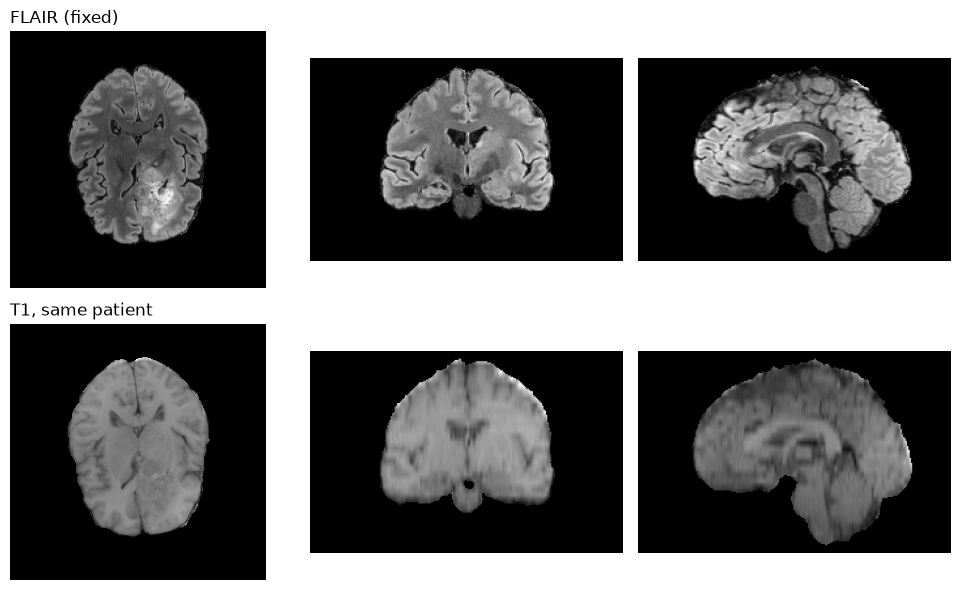

In [3]:
def show(img, title, ax_row):
    a = sitk.GetArrayFromImage(img)      # numpy order is (z, y, x)
    z, y, x = [s // 2 for s in a.shape]
    for ax, sl in zip(ax_row, [a[z], a[:, y, :], a[:, :, x]]):
        ax.imshow(sl, cmap="gray", origin="lower"); ax.axis("off")
    ax_row[0].set_title(title, loc="left")

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
show(fixed, "FLAIR (fixed)", axes[0]); show(t1, "T1, same patient", axes[1])
plt.tight_layout(); plt.show()


In [4]:
# Rotate around the centre of the image, not around voxel (0,0,0)
center = fixed.TransformContinuousIndexToPhysicalPoint(
    [(s - 1) / 2 for s in fixed.GetSize()])

true_tx = sitk.Euler3DTransform()
true_tx.SetCenter(center)
true_tx.SetRotation(np.deg2rad(5), np.deg2rad(-3), np.deg2rad(10))  # around x, y, z
true_tx.SetTranslation((8.0, -5.0, 3.0))                            # mm

def warp(img, tx):
    # Resample asks, for every voxel of the output: "where do I read from in img?"
    return sitk.Resample(img, img, tx, sitk.sitkLinear, 0.0, sitk.sitkFloat32)

moving_flair = warp(fixed, true_tx.GetInverse())   # FLAIR moved: same contrast
moving_t1    = warp(t1,    true_tx.GetInverse())   # T1 moved: different contrast

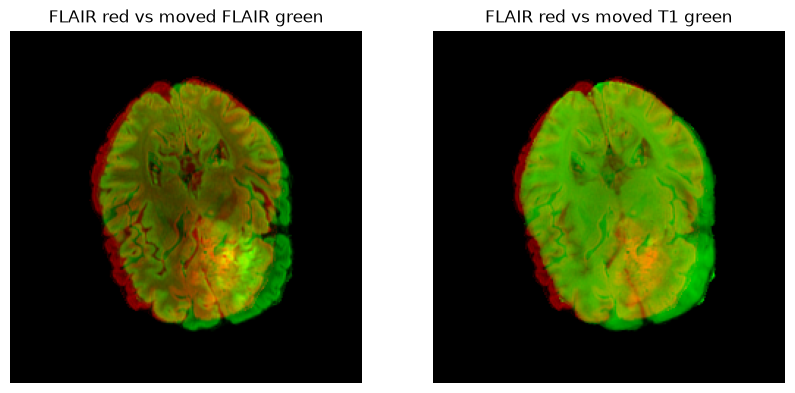

In [5]:
def overlay(a, b, title):
    A = sitk.GetArrayFromImage(a); B = sitk.GetArrayFromImage(b)
    z = A.shape[0] // 2
    norm = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-6)
    rgb = np.stack([norm(A[z]), norm(B[z]), np.zeros_like(A[z])], -1)
    plt.imshow(rgb, origin="lower"); plt.title(title); plt.axis("off")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); overlay(fixed, moving_flair, "FLAIR red vs moved FLAIR green")
plt.subplot(1, 2, 2); overlay(fixed, moving_t1,    "FLAIR red vs moved T1 green")
plt.show()

In [6]:
def register(fixed, moving, metric):
    R = sitk.ImageRegistrationMethod()

    # (2) Similarity metric
    if metric == "mse":
        R.SetMetricAsMeanSquares()
    else:
        R.SetMetricAsMattesMutualInformation(numberOfHistogramBins=50)
    R.SetMetricSamplingStrategy(R.RANDOM)
    R.SetMetricSamplingPercentage(0.05, seed=42)   # score on 5% of voxels: faster, still fine

    R.SetInterpolator(sitk.sitkLinear)

    # (3) Optimizer
    R.SetOptimizerAsRegularStepGradientDescent(
        learningRate=1.0, minStep=1e-4, numberOfIterations=300,
        gradientMagnitudeTolerance=1e-8)
    R.SetOptimizerScalesFromPhysicalShift()   # makes 1 radian and 1 mm comparable

    # Coarse to fine: blurry low-res first, then sharper
    R.SetShrinkFactorsPerLevel([4, 2, 1])
    R.SetSmoothingSigmasPerLevel([2, 1, 0])
    R.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

    # (1) Transform model: rigid, starting with image centres lined up
    init = sitk.CenteredTransformInitializer(
        fixed, moving, sitk.Euler3DTransform(),
        sitk.CenteredTransformInitializerFilter.GEOMETRY)
    R.SetInitialTransform(init, inPlace=False)

    t0 = time.time()
    found = R.Execute(fixed, moving)
    return found, R.GetOptimizerStopConditionDescription(), time.time() - t0

In [7]:
brain = sitk.GetArrayFromImage(fixed) > 0             # skull-stripped, so >0 = brain
idx = np.argwhere(brain)[::500][:, ::-1].astype(float)  # every 500th brain voxel, (x,y,z)
pts = [fixed.TransformContinuousIndexToPhysicalPoint(p.tolist()) for p in idx]
print(len(pts), "test points")

def tre(found, truth):
    a = np.array([truth.TransformPoint(p) for p in pts])
    b = np.array([found.TransformPoint(p) for p in pts])
    d = np.linalg.norm(a - b, axis=1)
    return d.mean(), d.max()

2961 test points


In [8]:
rows = []
for pair, mov in [("FLAIR to FLAIR", moving_flair), ("FLAIR to T1", moving_t1)]:
    for metric in ["mse", "mi"]:
        found, stop, secs = register(fixed, mov, metric)
        m, mx = tre(found, true_tx)
        rows.append(dict(pair=pair, metric=metric, tre_mean_mm=round(m, 2),
                         tre_max_mm=round(mx, 2), seconds=round(secs, 1)))
        print(pair, metric, f"TRE {m:.2f} mm (max {mx:.2f})", stop)
pd.DataFrame(rows)

FLAIR to FLAIR mse TRE 0.01 mm (max 0.01) RegularStepGradientDescentOptimizerv4: Step too small after 22 iterations. Current step (6.10352e-05) is less than minimum step (0.0001).
FLAIR to FLAIR mi TRE 0.01 mm (max 0.01) RegularStepGradientDescentOptimizerv4: Step too small after 23 iterations. Current step (6.10352e-05) is less than minimum step (0.0001).
FLAIR to T1 mse TRE 1.13 mm (max 1.20) RegularStepGradientDescentOptimizerv4: Step too small after 27 iterations. Current step (6.10352e-05) is less than minimum step (0.0001).
FLAIR to T1 mi TRE 0.37 mm (max 0.47) RegularStepGradientDescentOptimizerv4: Step too small after 27 iterations. Current step (6.10352e-05) is less than minimum step (0.0001).


,pair,metric,tre_mean_mm,tre_max_mm,seconds
0,FLAIR to FLAIR,mse,0.01,0.01,2.7
1,FLAIR to FLAIR,mi,0.01,0.01,3.7
2,FLAIR to T1,mse,1.13,1.20,3.1
3,FLAIR to T1,mi,0.37,0.47,5.3


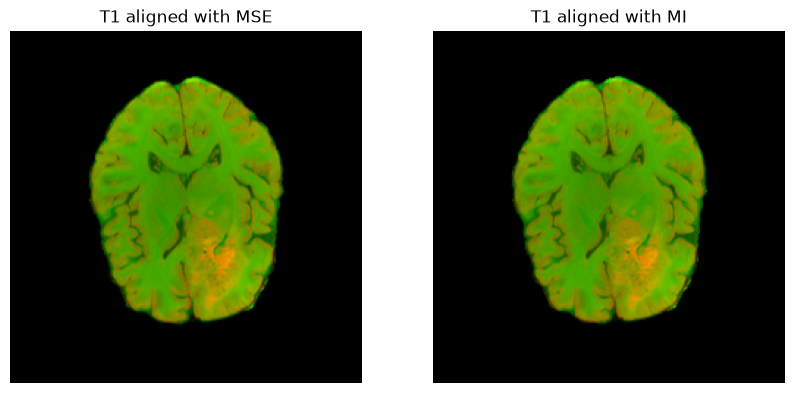

In [9]:
found_mse, _, _ = register(fixed, moving_t1, "mse")
found_mi,  _, _ = register(fixed, moving_t1, "mi")
fixed_back = lambda f: sitk.Resample(moving_t1, fixed, f, sitk.sitkLinear, 0.0)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1); overlay(fixed, fixed_back(found_mse), "T1 aligned with MSE")
plt.subplot(1, 2, 2); overlay(fixed, fixed_back(found_mi),  "T1 aligned with MI")
plt.savefig("../figures/mse_vs_mi_overlay.png", dpi=150, bbox_inches="tight"); plt.show()

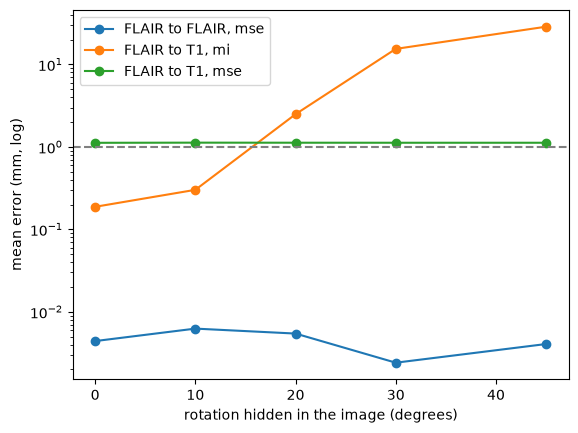

In [10]:
sweep = []
for angle in [0, 10, 20, 30, 45]:
    truth = sitk.Euler3DTransform(); truth.SetCenter(center)
    truth.SetRotation(0, 0, np.deg2rad(angle)); truth.SetTranslation((8.0, -5.0, 3.0))
    mf = warp(fixed, truth.GetInverse()); mt = warp(t1, truth.GetInverse())
    for pair, mov, metric in [("FLAIR to FLAIR", mf, "mse"),
                              ("FLAIR to T1", mt, "mse"),
                              ("FLAIR to T1", mt, "mi")]:
        found, _, _ = register(fixed, mov, metric)
        sweep.append(dict(angle=angle, pair=pair, metric=metric,
                          tre_mean_mm=tre(found, truth)[0]))
sweep = pd.DataFrame(sweep)

for (pair, metric), g in sweep.groupby(["pair", "metric"]):
    plt.plot(g.angle, g.tre_mean_mm, "o-", label=f"{pair}, {metric}")
plt.axhline(1, ls="--", c="gray"); plt.yscale("log")
plt.xlabel("rotation hidden in the image (degrees)"); plt.ylabel("mean error (mm, log)")
plt.legend(); plt.savefig("../figures/capture_range.png", dpi=150, bbox_inches="tight"); plt.show()
sweep.to_csv("../results/capture_range.csv", index=False)
pd.DataFrame(rows).to_csv("../results/mse_vs_mi.csv", index=False)